# Part A, step 1: motor imagery ceiling with a few electrodes

**Goal of this notebook:** understand every step of a BCI pipeline by building one yourself, then run a tiny version of the actual project: *how well can you decode left vs. right hand imagery using only the few electrodes a cheap headset like our NeuroPawn would place over the motor area?*

**How to use it**
- Cells with `___` are blanks for you to fill in. Each has a `# TODO` explaining what goes there.
- Before running a cell, **predict** the output (a shape, a number, roughly what a plot looks like). Being wrong is where the learning happens.
- `check(...)` cells tell you if you got it right.
- Stuck for more than ~10 minutes? Look at the matching cell in `part_a_step1_SOLUTIONS.ipynb`, then close it and type the answer yourself.

**The dataset:** BCI Competition IV 2a (`BNCI2014_001` in MOABB). 9 people, 22 gel electrodes, 250 Hz, 2 sessions on different days. Each session has 72 trials per class. We use only left hand vs. right hand.

**Our channel plan:** the NeuroPawn Knight Board has 8 channels and we choose where they go. For motor imagery we use 5 sites over and around the motor strip: **Fz, C3, Cz, C4, Pz**. Fz doubles as a control electrode, since it sits away from the hand motor areas. Change `MI_CHANNELS` if the team settles on different sites.

**The whole pipeline in one line:** `X` (trials × channels × time) → features → classifier → accuracy on trials it never saw.

In [1]:
# Install EEG benchmarking deps (MOABB, pyRiemann, sklearn) into the active kernel's venv.
# Run once, then restart the kernel.
%pip install moabb pyriemann scikit-learn matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [9]:
# Run once in your terminal (not here), inside a virtual environment:
#   pip install moabb pyriemann scikit-learn matplotlib scipy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import welch

def check(ok, msg_ok="Correct!", msg_bad="Not quite, look at the TODO again."):
    print(msg_ok if ok else msg_bad)


check(np)
check(plt)
check(pd)
check(welch)

Correct!
Correct!
Correct!
Correct!


## 1. Load the data

MOABB has two pieces here:
- a **dataset** object (where the data comes from)
- a **paradigm** object (how to cut it into trials: which events, which channels, which frequency band)

`LeftRightImagery` keeps only left-hand and right-hand trials, band-pass filters to 8–32 Hz (mu + beta, where motor imagery lives), and cuts one epoch per trial.

The first run downloads the data (a few hundred MB for subject 1). After that it's cached.

In [ ]:
# Data + task definition
#   BNCI2014_001     - public motor imagery dataset (BCI Competition IV 2a): 9 subjects, 22 EEG channels, 250 Hz
#   LeftRightImagery - MOABB paradigm that turns raw EEG into labeled left/right-hand epochs ready for classification
from moabb.datasets import BNCI2014_001 # imports the actual dataset to use
from moabb.paradigms import LeftRightImagery # imports the LeftRightImagery class

MI_CHANNELS = ["Fz", "C3", "Cz", "C4", "Pz"]   # sites we plan to record on the NeuroPawn

dataset = BNCI2014_001()
# TODO: pass our channel list to the paradigm so it only keeps those electrodes
paradigm = LeftRightImagery(channels=MI_CHANNELS)

# TODO: load subject 1 only (subjects takes a list)
X, y, meta = paradigm.get_data(dataset=dataset, subjects=[1])

Attempting to create new mne-python configuration file:
/Users/domenicj/.mne/mne-python.json
Could not read the /Users/domenicj/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 5 of 769 manifest files (16 concurrent downloads).


Overall:  46%|████▌     | 5.73k/12.6k [00:00<00:00, 8.45kB/s]


Finished downloading nm000139 v1.0.3.
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).


S3: 100%|██████████| 82.6M/82.6M [00:15<00:00, 5.44MB/s]


Finished downloading nm000139 v1.0.3.


/Users/domenicj/miniconda3/envs/TNT-EEG/lib/python3.14/site-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/Users/domenicj/miniconda3/envs/TNT-EEG/lib/python3.14/site-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/Users/domenicj/miniconda3/envs/TNT-EEG/lib/python3.14/site-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/Users/domenicj/miniconda3/envs/TNT-EEG/lib/python3.14/site-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in M

Not quite, look at the TODO again.


In [12]:
check(X.shape == (288,5,1001))

Correct!


**Predict before running the next cell:** what shape will `X` have? Think: how many trials (2 sessions × 72 trials × 2 classes), how many channels, and how many time samples (each epoch is 4 seconds at 250 Hz)?

In [14]:
print("X shape:", X.shape)          # (n_trials, n_channels, n_times)
print("y examples:", y[:6])
print("classes and counts:", np.unique(y, return_counts=True))
print(meta.head())
print("sessions:", meta["session"].unique())

# TODO: fill in the number of channels you expect
check(X.shape[1] == 5)

X shape: (288, 5, 1001)
y examples: ['right_hand' 'left_hand' 'left_hand' 'right_hand' 'right_hand'
 'left_hand']
classes and counts: (array(['left_hand', 'right_hand'], dtype='<U10'), array([144, 144]))
   subject session run
0        1  0train   0
1        1  0train   0
2        1  0train   0
3        1  0train   0
4        1  0train   0
sessions: <StringArray>
['0train', '1test']
Length: 2, dtype: str
Correct!


`meta` tells you which session and run each trial came from. That matters later: to test fairly, the model must never train on the trials it's tested on, and ideally the test trials come from *later* in time than the training ones.

For now we work inside **one session** (one day of recording).

In [18]:
sessions = meta["session"].unique()
in_s1 = (meta["session"] == sessions[0]).to_numpy()

# TODO: select the trials (and their labels) from the first session only
X1 = X[:144] # slices the X on the first 144 rows/trials
y1 = y[:144] # slices the y on the first 144 rows/trials to label each X either ['left_hand','right_hand']

print(X1.shape, np.unique(y1, return_counts=True))
check(X1.shape[0] == 144, "Correct: 144 trials in one session.", "Expected 144 trials, check your mask.")

(144, 5, 1001) (array(['left_hand', 'right_hand'], dtype='<U10'), array([72, 72]))
Correct: 144 trials in one session.


## 2. Look at the signal (no machine learning yet)

Before any model, check that the brain effect you expect is actually there.

**The expected effect (ERD):** imagining your *right* hand weakens the mu rhythm (8–13 Hz) over the *left* motor cortex, at **C3**. Imagining your *left* hand weakens it at **C4**.

So: power at C3 should be *lower* on right-hand trials than on left-hand trials, and the opposite at C4.

We measure power with Welch's method: it estimates how much energy the signal has at each frequency.

In [21]:
FS = 250   # samples per second

# Power spectrum of every trial and channel at once.
freqs, psd = welch(X1, fs=FS, nperseg=FS)    # psd shape: (trials, channels, freqs)
print("psd shape:", psd.shape)

# TODO: make a boolean mask that is True for frequencies in the mu band (8 to 13 Hz)
mu = (freqs >= 8) & (freqs <= 13)

# Average power in the mu band, per trial and channel, in log units (EEG power is very skewed)
mu_power = np.log(psd[:, :, mu].mean(axis=2))     # shape (trials, channels)

c3 = MI_CHANNELS.index("C3")
# TODO: get the column index for C4 the same way
c4 = MI_CHANNELS.index("C4")

for name, ch in [("C3", c3), ("C4", c4)]:
    left = mu_power[y1 == "left_hand", ch].mean()
    right = mu_power[y1 == "right_hand", ch].mean()
    print(f"{name}: left-hand trials {left:.3f}   right-hand trials {right:.3f}")

psd shape: (144, 5, 126)
C3: left-hand trials 0.305   right-hand trials 0.218
C4: left-hand trials 0.392   right-hand trials 0.419


**What to look for:** at C3, right-hand trials should be lower. At C4, left-hand trials should be lower. If you see that crossed pattern, the neural signal is there.

The difference may be small in averages and not perfect for every subject. Some people don't produce clear ERD, which is a known issue in motor imagery (sometimes called "BCI inefficiency").

Now see it per trial:

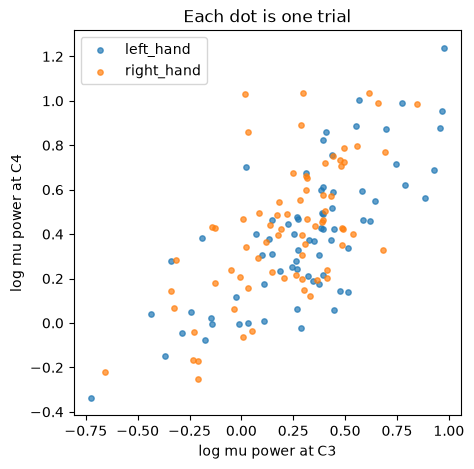

In [22]:
fig, ax = plt.subplots(figsize=(5, 5))
for label, color in [("left_hand", "tab:blue"), ("right_hand", "tab:orange")]:
    m = y1 == label
    ax.scatter(mu_power[m, c3], mu_power[m, c4], s=15, alpha=0.7, label=label, color=color)
ax.set_xlabel("log mu power at C3")
ax.set_ylabel("log mu power at C4")
ax.legend()
ax.set_title("Each dot is one trial")
plt.show()

**Question for you:** do the two colors separate? Probably partly, with a lot of overlap. That overlap is single-trial noise, and it's why EEG decoding is hard. A classifier's job is to draw the best line through this cloud.

## 3. The simplest classifier you fully understand

**Features:** log power in mu (8–13 Hz) and beta (13–30 Hz) at C3 and C4. That's 4 numbers per trial.

**Classifier:** LDA (linear discriminant analysis). It finds the straight line that best separates the two classes. It's the classic BCI classifier: fast, few parameters, hard to overfit.

**Evaluation:** 5-fold cross-validation **without shuffling**. The trials stay in time order, so each test fold is a block of consecutive trials. Shuffling would let the model train on trials recorded seconds before and after each test trial, which inflates accuracy because EEG drifts slowly over time.

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import KFold, cross_val_score

def bandpower_features(X, chans, bands=((8, 13), (13, 30))):
    # Log band power for each (channel, band) pair. Returns (trials, n_chans * n_bands).
    freqs, psd = welch(X, fs=FS, nperseg=FS)
    feats = []
    for lo, hi in bands:
        band = (freqs >= lo) & (freqs <= hi)
        feats.append(np.log(psd[:, chans][:, :, band].mean(axis=2)))
    return np.concatenate(feats, axis=1)

# TODO: build features from C3 and C4 only (use the indices you made above)
F = bandpower_features(X1, chans=[___, ___])
print("feature matrix:", F.shape)   # predict this first!

# TODO: time-ordered folds. Should shuffle be True or False?
cv = KFold(n_splits=5, shuffle=___)

scores = cross_val_score(LinearDiscriminantAnalysis(), F, y1, cv=cv)
print("accuracy per fold:", np.round(scores, 2))
print(f"mean accuracy: {scores.mean():.3f}   (chance = 0.5)")

Write down this number. It's your baseline.

## 4. Sanity checks: prove the number means something

A result you can't break isn't a result you understand. Two checks every BCI project should run:

**Check A: shuffled labels.** Randomly scramble `y`. Now there's no real relationship between brain data and labels, so accuracy *must* drop to about 50%. If it doesn't, your pipeline is leaking information somewhere.

In [ ]:
rng = np.random.default_rng(0)
shuffled_scores = []
for i in range(20):
    # TODO: make a randomly permuted copy of y1
    y_fake = ___
    shuffled_scores.append(cross_val_score(LinearDiscriminantAnalysis(), F, y_fake, cv=cv).mean())

print(f"real labels:     {scores.mean():.3f}")
print(f"shuffled labels: {np.mean(shuffled_scores):.3f} +/- {np.std(shuffled_scores):.3f}")

The spread of the shuffled scores also tells you how far above 50% you need to be before a result is believable with only 144 trials. Anything inside that spread could be luck.

**Check B: the wrong electrode.** Fz sits over the frontal lobe, not the hand motor area. Decoding from Fz alone should be much worse than from C3 + C4. If Fz did *better*, you'd suspect it's picking up something else, like eye or face muscle activity.

In [ ]:
fz = MI_CHANNELS.index("Fz")
# TODO: features from Fz alone
F_fz = bandpower_features(X1, chans=[___])
fz_score = cross_val_score(LinearDiscriminantAnalysis(), F_fz, y1, cv=cv).mean()
print(f"C3 + C4: {scores.mean():.3f}    Fz only: {fz_score:.3f}")

## 5. A real method: Riemannian tangent space

Instead of hand-picking frequency bands and channels, summarize each trial as a **covariance matrix**: how much each channel varies, and how each pair of channels varies together. With 5 channels, that's a 5×5 matrix per trial. It captures both power and spatial pattern.

Covariance matrices live on a curved space, so we "flatten" them around their average (the **tangent space**) into normal feature vectors, then use logistic regression.

This is three steps chained into one scikit-learn **pipeline**, which means cross-validation re-fits every step on each training fold. That's important: if the tangent-space reference point were computed on all trials including test trials, information would leak.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

riemann = make_pipeline(
    Covariances(estimator="oas"),   # one covariance matrix per trial ("oas" = stable estimate for small samples)
    TangentSpace(),                 # flatten to vectors
    LogisticRegression(max_iter=1000),
)

# Predict first: what shape is one covariance matrix? What's the length of one tangent-space vector?
covs = Covariances(estimator="oas").fit_transform(X1)
print("covariances:", covs.shape)
ts = TangentSpace().fit_transform(covs)
print("tangent vectors:", ts.shape)    # hint: a symmetric 5x5 matrix has 5*6/2 unique numbers

# TODO: cross-validate the riemann pipeline on the raw epochs X1 (not the hand-made features F)
riemann_scores = cross_val_score(riemann, ___, y1, cv=cv)
print(f"Riemannian: {riemann_scores.mean():.3f}   vs   band power + LDA: {scores.mean():.3f}")

## 6. Your first Part A result: channel ablation

This is the project in miniature. How does accuracy change as we give the decoder fewer electrodes?

Channel subsets are chosen **in advance** based on where motor imagery happens, not by looking at which ones score best. Choosing after seeing scores would inflate the result.

In [ ]:
subsets = {
    "5 ch (all planned MI sites)": ["Fz", "C3", "Cz", "C4", "Pz"],
    "3 ch (C3, Cz, C4)":           ["C3", "Cz", "C4"],
    "2 ch (C3, C4)":               ["C3", "C4"],
    "1 ch (C3)":                   ["C3"],
    "1 ch (Fz, control)":          ["Fz"],
}

results = {}
for name, chans in subsets.items():
    idx = [MI_CHANNELS.index(c) for c in chans]
    Xs = X1[:, idx, :]
    if len(idx) >= 2:
        model = riemann
        acc = cross_val_score(model, Xs, y1, cv=cv).mean()
    else:
        # One channel has no "pair" information, so covariance = just power. Use band power + LDA.
        acc = cross_val_score(LinearDiscriminantAnalysis(), bandpower_features(Xs, chans=[0]), y1, cv=cv).mean()
    results[name] = acc
    print(f"{name:30s} {acc:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(list(results.keys()), list(results.values()))
ax.axvline(0.5, color="gray", linestyle="--", label="chance")
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("accuracy (subject 1, session 1)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

## 7. Calibration time: how much training data does each user need?

The other main axis of the project. A real headset user doesn't want to sit through 10 minutes of training trials.

Setup: hold out the **last 40 trials** of the session as a fixed test set. Train on only the first N trials before it. Because the test set is always later in time, this mimics real use: calibrate first, then use the BCI.

In this dataset one trial takes roughly 7–8 seconds including rest, so 8 trials is about 1 minute.

In [ ]:
n_test = 40
X_train_pool, y_train_pool = X1[:-n_test], y1[:-n_test]
X_test, y_test = X1[-n_test:], y1[-n_test:]

for n_train in [8, 16, 40, 104]:
    Xtr, ytr = X_train_pool[:n_train], y_train_pool[:n_train]
    if len(np.unique(ytr)) < 2:
        print(f"{n_train:4d} trials: only one class in training set, skipping")
        continue
    # TODO: fit the riemann pipeline on the training trials, then score it on the test trials
    riemann.fit(___, ___)
    acc = riemann.score(___, ___)
    print(f"{n_train:4d} training trials (~{n_train * 7.5 / 60:.1f} min): accuracy {acc:.3f}")

With 40 test trials, each single accuracy is noisy (one trial = 2.5 percentage points). In the real project you'd repeat this across all 9 subjects and average. That's exactly what MOABB's evaluation tools are for, which is the next step.

## 8. Scale up with MOABB (all 9 subjects)

Everything above was one person on one day. MOABB runs the same pipeline across every subject with a standard protocol so results are comparable to published benchmarks.

`WithinSessionEvaluation` does cross-validation inside each session for each subject. This takes a few minutes the first time because it downloads all 9 subjects.

In [ ]:
from moabb.evaluations import WithinSessionEvaluation

pipelines = {
    "TS+LR (5 ch)": make_pipeline(Covariances("oas"), TangentSpace(), LogisticRegression(max_iter=1000)),
}

evaluation = WithinSessionEvaluation(
    paradigm=LeftRightImagery(channels=MI_CHANNELS),
    datasets=[dataset],
    overwrite=False,
)
mo_results = evaluation.process(pipelines)

print(mo_results[["subject", "session", "score"]])
print("\nmean score per subject:")
print(mo_results.groupby("subject")["score"].mean().round(3))

**Things to notice**
- MOABB's default score for two classes is ROC AUC, not accuracy. Chance is still 0.5. Check which metric your results table uses before comparing numbers.
- Look at the spread across subjects. Some will be near 0.9, some near chance. Reporting only the average hides this, so always show per-subject results.

## What you've built
- Loaded a public dataset restricted to the electrodes we plan to record
- Confirmed the neural effect (ERD) exists before modeling
- Built a classifier you understand line by line
- Proved it with shuffled labels and a control electrode
- Ran a real method, a channel ablation, and a calibration curve

That's the full skeleton of Part A. Next steps: repeat sections 6 and 7 across all subjects, then add the P300 and SSVEP paradigms with the same structure.